# CHSH game - An experimental Non-Local game
### (John Clauser, Michael Horne, Abner Shimony, and Richard Holt )

## Non-Local Game : 

#### A nonlocal game is a cooperative game where two players, Alice and Bob, work together to achieve a particular outcome. The game is run by a referee, who behaves according to strict guidelines that are known to Alice and Bob

###### !<img src="https://quantum.cloud.ibm.com/learning/images/courses/basics-of-quantum-information/entanglement-in-action/nonlocal-game.avif?dpl=0-1-1564-fd036b251a37" width="30%">


The CHSH game is a two-player nonlocal game involving Alice and Bob.

Alice receives a random input $$x\in\{0,1\}$$, and Bob receives a random input \(y\in\{0,1\}\). Each player produces a binary output \(a,b\in\{0,1\}\).

The players win when

$$
a\oplus b=x\land y.
$$

Therefore, the required relationship between their outputs is:

| Alice's input \(x\) | Bob's input \(y\) | Winning condition |
|:---:|:---:|:---:|
| 0 | 0 | \(a=b\) |
| 0 | 1 | \(a=b\) |
| 1 | 0 | \(a=b\) |
| 1 | 1 | \(a\neq b\) |

The inputs are chosen independently and uniformly at random.


The main objective is to compare the performance of:

1. A **classical strategy**
2. A **quantum strategy using entanglement**
3. A **real quantum hardware implementation**

The experiment demonstrates how quantum correlations can outperform the maximum performance achievable by classical strategies.

In [1]:
from qiskit import __version__
print(__version__)

2.5.2


## Classical Strategy: 

Before considering the quantum strategy, we first establish the best performance that can be achieved using a classical strategy.

Alice and Bob cannot communicate after receiving their inputs. They must therefore use a pre-agreed strategy to determine their outputs.

For the CHSH game, no classical strategy can win more than **75%** of the games:

$$
P_{\mathrm{classical}} \leq 75\%
$$

This classical limit provides the baseline against which we compare the quantum strategy.

The simulation below demonstrates the performance of a classical strategy over a large number of games.

In [13]:
def classical_strategy(x, y):
    # This function implements just one example of an optimal classical
    # strategy for the CHSH game. Other classical strategies can be
    # implemented by changing the bit values assigned to a and b.

    # Alice's answer
    if x == 0:
        a = 0
    elif x == 1:
        a = 1

    # Bob's answer
    if y == 0:
        b = 1
    elif y == 1:
        b = 0

    return a, b

In [14]:
NUM_GAMES = 1000
TOTAL_SCORE = 0

for _ in range(NUM_GAMES):
    TOTAL_SCORE += chsh_game(classical_strategy)

print("Fraction of games won:", TOTAL_SCORE / NUM_GAMES)

Fraction of games won: 0.752


In [2]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, array_to_latex
from qiskit.result import marginal_distribution
from qiskit.circuit.library import UGate
from math import pi
import random

In [17]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler

service = QiskitRuntimeService()

backend = service.backend("ibm_fez")
print(backend.name)

sampler = Sampler(mode=backend)

ibm_fez


C:\Users\gunda\AppData\Local\Temp\ipykernel_42164\646228404.py:9: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


## Quantum Strategy

The quantum strategy uses an entangled pair of qubits shared between Alice and Bob.

We prepare the Bell state

$$
|\Phi^+\rangle=
\frac{|00\rangle+|11\rangle}{\sqrt{2}}.
$$

This state is prepared from $$|00\rangle$$ using a Hadamard gate followed by a controlled-NOT gate:

$$
|00\rangle
\xrightarrow{H\otimes I}
\frac{|00\rangle+|10\rangle}{\sqrt{2}}
\xrightarrow{CX}
\frac{|00\rangle+|11\rangle}{\sqrt{2}}.
$$

The entanglement between the two qubits produces correlations that can exceed the classical CHSH limit.

---

In [3]:
def chsh_game(strategy):
    # This function runs the CHSH game, using the strategy (a function
    # from two bits to two bits), returning 1 for a win and 0 for a loss.

    # Choose x and y randomly
    x, y = random.randint(0, 1), random.randint(0, 1)

    # Use the strategy to determine a and b
    a, b = strategy(x, y)

    # Decide if the strategy wins or loses
    if (a != b) == (x & y):
        return 1  # Win
    return 0  # Lose

In [4]:
from math import pi

def chsh_circuit(x, y):
    # This function creates a `QuantumCircuit` implementing the quantum
    # strategy described above (including the e-bit preparation).

    qc = QuantumCircuit(2, 2)

    # Prepare an e-bit
    qc.h(0)
    qc.cx(0, 1)
    qc.barrier()

    # Alice's actions
    if x == 0:
        qc.ry(0, 0)
    else:
        qc.ry(-pi / 2, 0)
    qc.measure(0, 0)

    # Bob's actions
    if y == 0:
        qc.ry(-pi / 4, 1)
    else:
        qc.ry(pi / 4, 1)
    qc.measure(1, 1)

    return qc

(x,y) = (0,0)


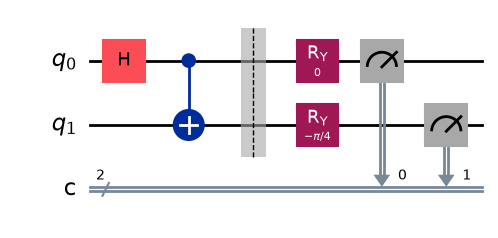

(x,y) = (0,1)


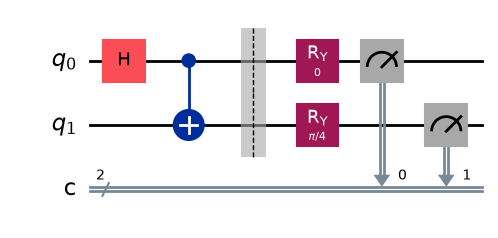

(x,y) = (1,0)


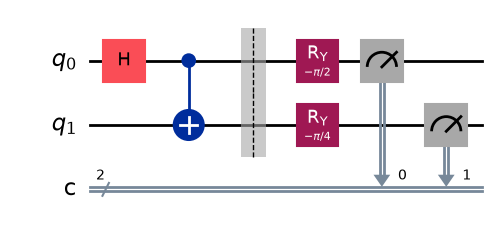

(x,y) = (1,1)


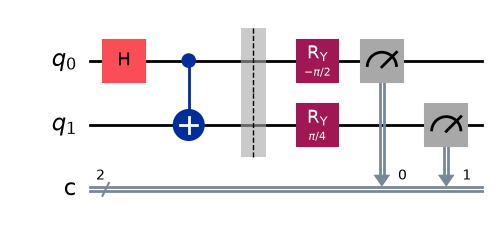

In [5]:
# Draw the four possible circuits

print("(x,y) = (0,0)")
display(chsh_circuit(0, 0).draw(output="mpl"))

print("(x,y) = (0,1)")
display(chsh_circuit(0, 1).draw(output="mpl"))

print("(x,y) = (1,0)")
display(chsh_circuit(1, 0).draw(output="mpl"))

print("(x,y) = (1,1)")
display(chsh_circuit(1, 1).draw(output="mpl"))

In [6]:
def quantum_strategy(x, y):
    # This function runs the appropriate quantum circuit defined above
    # one time and returns the measurement results

    # Setting `shots=1` to run the circuit once
    result = AerSimulator().run(chsh_circuit(x, y), shots=1).result()
    statistics = result.get_counts()

    # Determine the output bits and return them
    bits = list(statistics.keys())[0]
    a, b = bits[0], bits[1]
    return a, b

In [7]:
NUM_GAMES = 1000
TOTAL_SCORE = 0

for _ in range(NUM_GAMES):
    TOTAL_SCORE += chsh_game(quantum_strategy)

print("Fraction of games won:", TOTAL_SCORE / NUM_GAMES)

Fraction of games won: 0.851


## Measurement Settings

The measurement basis used by Alice and Bob depends on their respective inputs \(x\) and \(y\).

Since each input can take two possible values, there are four possible input combinations:

$$
(0,0),\quad(0,1),\quad(1,0),\quad(1,1).
$$

Each combination corresponds to a different pair of measurement settings.

The measurement settings are chosen so that the quantum correlations maximize the CHSH violation.


In [8]:
from qiskit_aer import AerSimulator

def calculate_correlation(x, y, shots=1000):
    """
    Calculate E_xy = <A B> for a fixed question pair (x, y).

    Measurement bits:
        0 -> +1
        1 -> -1
    """

    result = AerSimulator().run(
        chsh_circuit(x, y),
        shots=shots
    ).result()

    counts = result.get_counts()

    correlation_sum = 0

    for bitstring, count in counts.items():

        # Qiskit returns classical bits as c1 c0.
        # Our circuit measures:
        # q0 -> c0 (Alice)
        # q1 -> c1 (Bob)
        b = int(bitstring[0])   # Bob
        a = int(bitstring[1])   # Alice

        A = 1 if a == 0 else -1
        B = 1 if b == 0 else -1

        correlation_sum += A * B * count

    return correlation_sum / shots

In [9]:
shots = 10000

E00 = calculate_correlation(0, 0, shots)
E01 = calculate_correlation(0, 1, shots)
E10 = calculate_correlation(1, 0, shots)
E11 = calculate_correlation(1, 1, shots)

print(f"E00 = {E00:.4f}")
print(f"E01 = {E01:.4f}")
print(f"E10 = {E10:.4f}")
print(f"E11 = {E11:.4f}")

E00 = 0.7034
E01 = 0.7216
E10 = 0.7010
E11 = -0.7116


In [10]:
S = E00 + E01 + E10 - E11

print(f"\nCHSH S = {S:.4f}")
print(f"Classical bound = 2")
print(f"Quantum theoretical value = {2 * 2**0.5:.4f}")


CHSH S = 2.8376
Classical bound = 2
Quantum theoretical value = 2.8284


## Quantum Circuit Simulation

Before executing the circuits on real quantum hardware, we first simulate them locally.

This allows us to verify the circuit construction and measurement logic under ideal conditions, without hardware noise.

In [12]:
print("CHSH INEQUALITY EXPERIMENT")
print("-" * 35)

print(f"E(0,0) = {E00:+.4f}")
print(f"E(0,1) = {E01:+.4f}")
print(f"E(1,0) = {E10:+.4f}")
print(f"E(1,1) = {E11:+.4f}")

print("\nCHSH parameter:")
print(f"S = E00 + E01 + E10 - E11")
print(f"S = {S:.4f}")

print("\nClassical bound:")
print("|S| <= 2")

print("\nQuantum bound:")
print(f"|S| <= {2 * 2**0.5:.4f}")

if abs(S) > 2:
    print("\nRESULT: CHSH inequality is violated.")
else:
    print("\nRESULT: CHSH inequality is not violated.")

CHSH INEQUALITY EXPERIMENT
-----------------------------------
E(0,0) = +0.7034
E(0,1) = +0.7216
E(1,0) = +0.7010
E(1,1) = -0.7116

CHSH parameter:
S = E00 + E01 + E10 - E11
S = 2.8376

Classical bound:
|S| <= 2

Quantum bound:
|S| <= 2.8284

RESULT: CHSH inequality is violated.


## Four CHSH Circuits

We construct one quantum circuit for each possible input combination:

$$
(0,0),\quad(0,1),\quad(1,0),\quad(1,1).
$$

All four circuits begin with the same entangled Bell state. They differ only in the measurement operations determined by \(x\) and \(y\).

---

In [ ]:
# Step 2: Build the four CHSH circuits

qc00 = chsh_circuit(0, 0)
qc01 = chsh_circuit(0, 1)
qc10 = chsh_circuit(1, 0)   
qc11 = chsh_circuit(1, 1)

In [18]:
# Step 3: Transpile for IBM hardware

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target

pm = generate_preset_pass_manager(
    target=target,
    optimization_level=3
)

qc00_isa = pm.run(qc00)
qc01_isa = pm.run(qc01)
qc10_isa = pm.run(qc10)
qc11_isa = pm.run(qc11)

## Execution on Real Quantum Hardware

The same circuits are now executed on an IBM quantum processor.

Unlike an ideal simulator, real quantum hardware is affected by experimental imperfections such as:

- gate errors,
- measurement errors,
- decoherence,
- device-dependent noise.

Therefore, the hardware results are expected to differ slightly from the ideal theoretical predictions.

---

In [19]:
# Step 4: Run on real quantum hardware

import time

start_time = time.time()

shots = 1000

job = sampler.run(
    [qc00_isa, qc01_isa, qc10_isa, qc11_isa],
    shots=shots
)

print("Job ID:", job.job_id())

result = job.result()

end_time = time.time()

print(f"Elapsed time: {end_time - start_time:.2f} seconds")
print(f"Elapsed time: {(end_time - start_time)/60:.2f} minutes")

Job ID: dbapst7i0auc7392dbqg


KeyboardInterrupt: 

In [36]:
service = QiskitRuntimeService()

In [37]:
job_id = "dbapst7i0auc7392dbqg"

job = service.job(job_id)

In [38]:
print(job.status())

DONE


In [39]:
result = job.result()

print(result)

PrimitiveResult([SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=1000, num_bits=2>)), metadata={'circuit_metadata': {}, 'compilation': {'scheduler_timing': None, 'stretch_values': None}}), SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=1000, num_bits=2>)), metadata={'circuit_metadata': {}, 'compilation': {'scheduler_timing': None, 'stretch_values': None}}), SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=1000, num_bits=2>)), metadata={'circuit_metadata': {}, 'compilation': {'scheduler_timing': None, 'stretch_values': None}}), SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=1000, num_bits=2>)), metadata={'circuit_metadata': {}, 'compilation': {'scheduler_timing': None, 'stretch_values': None}})], metadata={'execution': {'execution_spans': ExecutionSpans([DoubleSliceSpan(<start='2026-10-19 06:03:31', stop='2026-10-19 06:03:34', size=4000>)])}, 'version': 2})


## Measurement Results

Each circuit is executed for multiple **shots**.

A shot represents one execution of the quantum circuit. After each execution, the two qubits are measured, producing one of four possible bitstrings:

$$
00,\quad01,\quad10,\quad11.
$$

These outcomes represent the binary outputs of Alice and Bob.

The frequency of each bitstring is used to estimate the corresponding probability.

---

In [41]:
for i, pub_result in enumerate(result):
    counts = pub_result.data.c.get_counts()
    print(f"Circuit {i}: {counts}")

Circuit 0: {'11': 400, '00': 414, '01': 94, '10': 92}
Circuit 1: {'10': 65, '00': 428, '11': 428, '01': 79}
Circuit 2: {'10': 75, '01': 91, '11': 416, '00': 418}
Circuit 3: {'10': 413, '11': 70, '01': 431, '00': 86}


In [42]:
counts00 = result[0].data.c.get_counts()
counts01 = result[1].data.c.get_counts()
counts10 = result[2].data.c.get_counts()
counts11 = result[3].data.c.get_counts()

# Correlation

To quantify the relationship between Alice's and Bob's outputs, we define the correlation

$$
E(x,y)=P(a=b)-P(a\neq b).
$$

From the four possible measurement outcomes,

$$
E(x,y)
=
P(00)+P(11)-P(01)-P(10).
$$

Thus:

- $E=+1$ corresponds to perfect correlation.
- $E=-1$ corresponds to perfect anti-correlation.
- $E=0$ corresponds to no net correlation.

We calculate the four correlation values

$$
E_{00},\quad E_{01},\quad E_{10},\quad E_{11}.
$$

In [43]:
def calculate_correlation_from_counts(counts, shots):
    
    correlation_sum = 0

    for bitstring, count in counts.items():

        b = int(bitstring[0])   # Bob
        a = int(bitstring[1])   # Alice

        A = 1 if a == 0 else -1
        B = 1 if b == 0 else -1

        correlation_sum += A * B * count

    return correlation_sum / shots

In [44]:
E00_hw = calculate_correlation_from_counts(counts00, shots)
E01_hw = calculate_correlation_from_counts(counts01, shots)
E10_hw = calculate_correlation_from_counts(counts10, shots)
E11_hw = calculate_correlation_from_counts(counts11, shots)

print(f"E00 = {E00_hw:.4f}")
print(f"E01 = {E01_hw:.4f}")
print(f"E10 = {E10_hw:.4f}")
print(f"E11 = {E11_hw:.4f}")

E00 = 0.6280
E01 = 0.7120
E10 = 0.6680
E11 = -0.6880


## CHSH Bell Parameter

The four correlation values are combined to obtain the CHSH parameter:

$$
S=E_{00}+E_{01}+E_{10}-E_{11}.
$$

For any classical strategy, the CHSH inequality requires

$$
|S|\leq 2.
$$

Quantum mechanics allows a larger value, with the maximum given by the Tsirelson bound:

$$
|S|\leq 2\sqrt{2}\approx 2.828.
$$

Therefore, observing

$$
|S|>2
$$

indicates a violation of the classical CHSH bound.

In [45]:
S_hw = E00_hw + E01_hw + E10_hw - E11_hw

print(f"\nHardware CHSH S = {S_hw:.4f}")
print(f"Classical bound = 2")
print(f"Quantum theoretical value = {2 * 2**0.5:.4f}")


Hardware CHSH S = 2.6960
Classical bound = 2
Quantum theoretical value = 2.8284


In [47]:
winning_conditions = [
    "correlated",      # Circuit 0
    "correlated",      # Circuit 1
    "correlated",      # Circuit 2
    "anti-correlated"  # Circuit 3
]

# CHSH Game Winning Probability

The CHSH parameter can also be expressed in terms of the probability of winning the game:

$$
P_{\text{win}}
=
\frac{1}{2}+\frac{S}{8}.
$$

For the classical limit,

$$
S=2
$$

gives

$$
P_{\text{classical}}=75\%.
$$

For the ideal quantum limit,

$$
S=2\sqrt{2},
$$

giving

$$
P_{\text{quantum}}
=
\frac{2+\sqrt{2}}{4}
\approx85.36\%.
$$

Thus, the CHSH game provides an intuitive interpretation of the Bell inequality: a quantum strategy can win more frequently than any classical strategy.

---

In [49]:
wins = []

for i, pub_result in enumerate(result):

    counts = pub_result.data.c.get_counts()
    shots = sum(counts.values())

    if winning_conditions[i] == "correlated":
        win_count = counts.get('00', 0) + counts.get('11', 0)
    else:
        win_count = counts.get('01', 0) + counts.get('10', 0)

    win_probability = win_count / shots

    wins.append(win_probability)

    print(f"Circuit {i}: {win_probability * 100:.2f}%")

overall = sum(wins) / len(wins)

print(f"\nOverall CHSH winning probability: {overall * 100:.2f}%")

Circuit 0: 81.40%
Circuit 1: 85.60%
Circuit 2: 83.40%
Circuit 3: 84.40%

Overall CHSH winning probability: 83.70%


# CHSH Experiment — Results and Analysis

This section collects the complete results of the CHSH experiment:

1. Classical strategy
2. Quantum strategy
3. Four measurement settings
4. Raw hardware counts
5. Measurement probabilities
6. Correlation values E(x,y)
7. CHSH parameter S
8. CHSH game winning probability
9. Comparison with classical and quantum limits

In [50]:
# ============================================================
# Structured CHSH Results
# ============================================================

settings = [
    {
        "circuit": 0,
        "x": 0,
        "y": 0,
        "winning_condition": "correlated"
    },
    {
        "circuit": 1,
        "x": 0,
        "y": 1,
        "winning_condition": "correlated"
    },
    {
        "circuit": 2,
        "x": 1,
        "y": 0,
        "winning_condition": "correlated"
    },
    {
        "circuit": 3,
        "x": 1,
        "y": 1,
        "winning_condition": "anti-correlated"
    }
]

chsh_results = []

for setting, pub_result in zip(settings, result):

    counts = pub_result.data.c.get_counts()
    shots = sum(counts.values())

    n00 = counts.get("00", 0)
    n01 = counts.get("01", 0)
    n10 = counts.get("10", 0)
    n11 = counts.get("11", 0)

    # Probabilities
    probabilities = {
        "00": n00 / shots,
        "01": n01 / shots,
        "10": n10 / shots,
        "11": n11 / shots
    }

    # Correlation:
    # same bits  -> +1
    # different  -> -1
    correlation = (
        n00 + n11 - n01 - n10
    ) / shots

    # Winning count
    if setting["winning_condition"] == "correlated":
        winning_count = n00 + n11
    else:
        winning_count = n01 + n10

    winning_probability = winning_count / shots

    chsh_results.append({
        **setting,

        "shots": shots,

        "counts": {
            "00": n00,
            "01": n01,
            "10": n10,
            "11": n11
        },

        "probabilities": probabilities,

        "correlation": correlation,

        "winning_count": winning_count,

        "winning_probability": winning_probability
    })

chsh_results

[{'circuit': 0,
  'x': 0,
  'y': 0,
  'winning_condition': 'correlated',
  'shots': 1000,
  'counts': {'00': 414, '01': 94, '10': 92, '11': 400},
  'probabilities': {'00': 0.414, '01': 0.094, '10': 0.092, '11': 0.4},
  'correlation': 0.628,
  'winning_count': 814,
  'winning_probability': 0.814},
 {'circuit': 1,
  'x': 0,
  'y': 1,
  'winning_condition': 'correlated',
  'shots': 1000,
  'counts': {'00': 428, '01': 79, '10': 65, '11': 428},
  'probabilities': {'00': 0.428, '01': 0.079, '10': 0.065, '11': 0.428},
  'correlation': 0.712,
  'winning_count': 856,
  'winning_probability': 0.856},
 {'circuit': 2,
  'x': 1,
  'y': 0,
  'winning_condition': 'correlated',
  'shots': 1000,
  'counts': {'00': 418, '01': 91, '10': 75, '11': 416},
  'probabilities': {'00': 0.418, '01': 0.091, '10': 0.075, '11': 0.416},
  'correlation': 0.668,
  'winning_count': 834,
  'winning_probability': 0.834},
 {'circuit': 3,
  'x': 1,
  'y': 1,
  'winning_condition': 'anti-correlated',
  'shots': 1000,
  'coun

In [51]:
for r in chsh_results:

    print(f"\nCircuit {r['circuit']}  "
          f"(x,y)=({r['x']},{r['y']})")

    print("Counts:", r["counts"])

    print("Probabilities:")

    for bitstring, probability in r["probabilities"].items():
        print(f"  {bitstring}: {probability * 100:.2f}%")

    print(f"Correlation E = {r['correlation']:.4f}")

    print(
        f"Winning probability = "
        f"{r['winning_probability'] * 100:.2f}%"
    )


Circuit 0  (x,y)=(0,0)
Counts: {'00': 414, '01': 94, '10': 92, '11': 400}
Probabilities:
  00: 41.40%
  01: 9.40%
  10: 9.20%
  11: 40.00%
Correlation E = 0.6280
Winning probability = 81.40%

Circuit 1  (x,y)=(0,1)
Counts: {'00': 428, '01': 79, '10': 65, '11': 428}
Probabilities:
  00: 42.80%
  01: 7.90%
  10: 6.50%
  11: 42.80%
Correlation E = 0.7120
Winning probability = 85.60%

Circuit 2  (x,y)=(1,0)
Counts: {'00': 418, '01': 91, '10': 75, '11': 416}
Probabilities:
  00: 41.80%
  01: 9.10%
  10: 7.50%
  11: 41.60%
Correlation E = 0.6680
Winning probability = 83.40%

Circuit 3  (x,y)=(1,1)
Counts: {'00': 86, '01': 431, '10': 413, '11': 70}
Probabilities:
  00: 8.60%
  01: 43.10%
  10: 41.30%
  11: 7.00%
Correlation E = -0.6880
Winning probability = 84.40%


In [52]:
# ============================================================
# CHSH Analysis
# ============================================================

E00 = chsh_results[0]["correlation"]
E01 = chsh_results[1]["correlation"]
E10 = chsh_results[2]["correlation"]
E11 = chsh_results[3]["correlation"]

# CHSH parameter
S = E00 + E01 + E10 - E11

# Game winning probability
P_win = 0.5 + S / 8

# Theoretical limits
classical_S = 2
quantum_S = 2 * (2 ** 0.5)

classical_P = 0.75
quantum_P = (2 + 2 ** 0.5) / 4

print("========== CHSH RESULTS ==========")

print(f"E00 = {E00:.4f}")
print(f"E01 = {E01:.4f}")
print(f"E10 = {E10:.4f}")
print(f"E11 = {E11:.4f}")

print(f"\nHardware CHSH S = {S:.4f}")

print(f"Classical bound = {classical_S:.4f}")
print(f"Quantum bound   = {quantum_S:.4f}")

print(f"\nHardware winning probability = {P_win * 100:.2f}%")
print(f"Classical winning probability = {classical_P * 100:.2f}%")
print(f"Quantum ideal winning probability = {quantum_P * 100:.2f}%")

print("\nCHSH violation:",
      S > classical_S)

print("Game advantage over classical:",
      (P_win - classical_P) * 100,
      "percentage points")

========== CHSH RESULTS ==========
E00 = 0.6280
E01 = 0.7120
E10 = 0.6680
E11 = -0.6880

Hardware CHSH S = 2.6960
Classical bound = 2.0000
Quantum bound   = 2.8284

Hardware winning probability = 83.70%
Classical winning probability = 75.00%
Quantum ideal winning probability = 85.36%

CHSH violation: True
Game advantage over classical: 8.699999999999996 percentage points


In [57]:

import pandas as pd

results_table = pd.DataFrame([
    {
        "Circuit": r["circuit"],
        "x": r["x"],
        "y": r["y"],
        "00 (%)": r["probabilities"]["00"] * 100,
        "01 (%)": r["probabilities"]["01"] * 100,
        "10 (%)": r["probabilities"]["10"] * 100,
        "11 (%)": r["probabilities"]["11"] * 100,
        "E(x,y)": r["correlation"],
        "Win (%)": r["winning_probability"] * 100
    }
    for r in chsh_results
])

results_table

,Circuit,x,y,00 (%),01 (%),10 (%),11 (%),"E(x,y)",Win (%)
0,0,0,0,41.4,9.4,9.2,40.0,0.628,81.4
1,1,0,1,42.8,7.9,6.5,42.8,0.712,85.6
2,2,1,0,41.8,9.1,7.5,41.6,0.668,83.4
3,3,1,1,8.6,43.1,41.3,7.0,-0.688,84.4


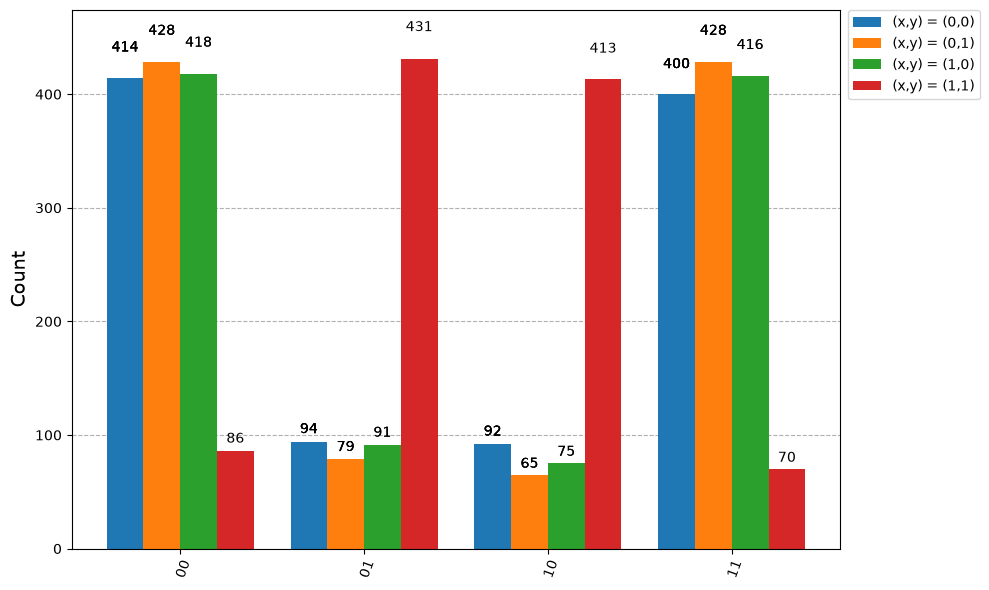

In [55]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

all_counts = [
    r["counts"]
    for r in chsh_results
]

plot_histogram(
    all_counts,
    legend=[
        "(x,y) = (0,0)",
        "(x,y) = (0,1)",
        "(x,y) = (1,0)",
        "(x,y) = (1,1)"
    ],
    figsize=(10, 6)
)

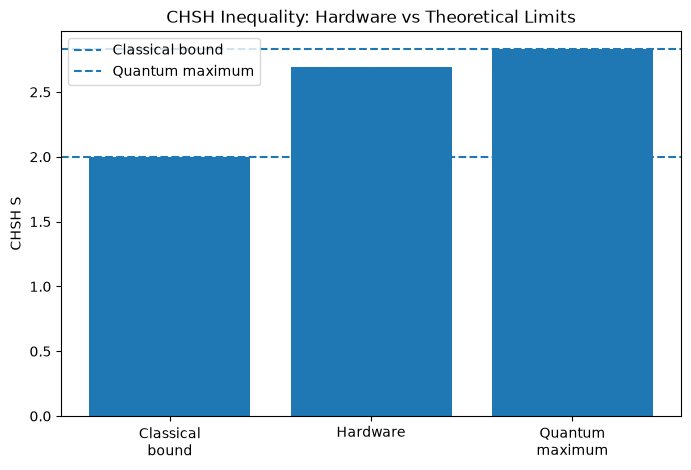

In [56]:
labels = [
    "Classical\nbound",
    "Hardware",
    "Quantum\nmaximum"
]

values = [
    classical_S,
    S,
    quantum_S
]

plt.figure(figsize=(8, 5))

bars = plt.bar(labels, values)

plt.axhline(2, linestyle="--", label="Classical bound")
plt.axhline(2 * (2 ** 0.5), linestyle="--",
            label="Quantum maximum")

plt.ylabel("CHSH S")
plt.title("CHSH Inequality: Hardware vs Theoretical Limits")
plt.legend()

plt.show()

## Results and Interpretation

The experimentally obtained correlations are used to calculate the CHSH parameter and the corresponding winning probability.

The experimental result can then be compared with:

- the classical limit,
- the ideal quantum prediction,
- the actual hardware result.

The difference between the ideal quantum value and the hardware result is expected because real quantum processors are noisy.


## Conclusion

The experiment demonstrates the CHSH game using an entangled pair of qubits.

The measured CHSH parameter is

$$
S=2.696,
$$

which exceeds the classical bound

$$
|S|\leq2.
$$

The corresponding experimental winning probability is

$$
P_{\text{win}}=83.70\%.
$$

This is above the classical limit of \(75\%\), while remaining below the ideal quantum prediction of approximately \(85.36\%\).

The result therefore demonstrates a CHSH violation using real quantum hardware under the implemented experimental conditions.